# 🚌 Auditoría Relacional e Ingeniería de Características sobre la Tabla Maestra (`maestro_gtfs.parquet`)

En este cuaderno se audita la **Tabla Analítica Maestra** consolidada mediante **Polars Lazy**, resultante de cruzar de forma íntegra las 8 tablas saneadas del catálogo **GTFS** de la EMT de Madrid. 

El objetivo doble de este laboratorio es:
1. **Verificar la integridad relacional** del *Golden Dataset* estructural (**2.232.015 tramos** y **37 variables base**) antes de acoplar fuentes externas en tiempo real.

2. **Diseñar y validar variables de interacción relacional (*Feature Engineering*)** que capturen la fricción urbana, la saturación en marquesina y la velocidad comercial programada, constituyendo la matriz de entrada del **Modelo 1 (*Baseline Estructural GTFS*)**.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual corporativa EMT Madrid
sns.set_theme(style="whitegrid", rc={"grid.linestyle": "--", "grid.alpha": 0.4})
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})

RUTA_MAESTRO = Path('../data/processed/maestro_gtfs.parquet')
assert RUTA_MAESTRO.exists(), f"No se encuentra el archivo maestro en {RUTA_MAESTRO}"

peso_mb = os.path.getsize(RUTA_MAESTRO) / (1024 * 1024)
df_maestro = pl.read_parquet(RUTA_MAESTRO)

print("====== AUDITORÍA ESTRUCTURAL DE LA TABLA MAESTRA (MAESTRO_GTFS.PARQUET) ======\n")
print(f"-> Dimensiones consolidadas : {df_maestro.height:,} filas x {df_maestro.width} columnas")
print(f"-> Tamaño en disco (ZSTD)   : {peso_mb:.2f} MB")
print(f"-> Memoria RAM ocupada      : {df_maestro.estimated_size('mb'):.2f} MB")
print("\n-> Listado completo de variables base disponibles:")
print(list(df_maestro.columns))


====== AUDITORÍA ESTRUCTURAL DE LA TABLA MAESTRA (MAESTRO_GTFS.PARQUET) ======

-> Dimensiones consolidadas : 2,232,015 filas x 46 columnas
-> Tamaño en disco (ZSTD)   : 69.30 MB
-> Memoria RAM ocupada      : 750.89 MB

-> Listado completo de variables base disponibles:
['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'shape_dist_traveled', 'tiempo_tramo_teorico_seg', 'distancia_tramo_m', 'hora_llegada_decimal', 'progreso_viaje_pct', 'densidad_paradas_acumuladas', 'route_id', 'service_id', 'trip_headsign', 'direction_id', 'block_id', 'shape_id', 'volumen_viajes_bloque', 'route_short_name', 'cabecera_ruta', 'destino_ruta', 'regimen_horario', 'stop_code', 'stop_name', 'stop_lat', 'stop_lon', 'calle_principal', 'en_alta_densidad_real', 'ubicacion_territorial', 'longitud_total_ruta_m', 'indice_sinuosidad', 'puntos_por_km', 'headway_medio_secs', 'headway_min_secs', 'autobuses_hora_medio', 'autobuses_hora_max', 'cobertura_total_franjas_secs', 'hora_entera', 'tramo_15

### 📘 Diccionario de Datos

Este notebook utiliza el diccionario de datos definido para el conjunto `maestro`.  

El documento completo se encuentra en:

👉 [`../docs/09_maestro_Dict.md`](../docs/09_maestro_Dict.md)

| Bloque Origen | Variable | Tipo de Dato | Descripción Operativa y Regla de Negocio |
| :--- | :--- | :--- | :--- |
| **Malla Horaria** (`stop_times`) | `trip_id` | `String` | Identificador único de la expedición comercial (`route_service_trip`). |
| **Malla Horaria** (`stop_times`) | `arrival_time` | `String` | Hora programada de llegada del autobús a la marquesina (`HH:MM:SS`). |
| **Malla Horaria** (`stop_times`) | `departure_time` | `String` | Hora programada de salida desde la marquesina (`HH:MM:SS`). |
| **Malla Horaria** (`stop_times`) | `stop_id` | `String` | Identificador único de la parada física en la red EMT. |
| **Malla Horaria** (`stop_times`) | `stop_sequence` | `Int32` | Orden correlativo de paso de la parada dentro del viaje (`1, 2, ..., N`). |
| **Malla Horaria** (`stop_times`) | `shape_dist_traveled` | `Int32` | Distancia acumulada en metros desde la cabecera de origen hasta la parada. |
| **Malla Horaria** (`stop_times`) | `tiempo_tramo_teorico_seg` | `Int32` | Duración planificada en segundos desde la parada inmediatamente anterior. |
| **Malla Horaria** (`stop_times`) | `distancia_tramo_m` | `Int32` | Longitud real del tramo en metros entre la parada anterior y la actual. |
| **Malla Horaria** (`stop_times`) | `hora_llegada_decimal` | `Float32` | Hora de llegada convertida a formato numérico continuo (`0.0` a `30.0+`). |
| **Malla Horaria** (`stop_times`) | `progreso_viaje_pct` | `Float32` | Fracción normalizada de avance del trayecto (`0.0` en origen a `1.0` en destino). |
| **Malla Horaria** (`stop_times`) | `densidad_paradas_acumuladas` | `Float32` | Ratio de paradas acumuladas por kilómetro recorrido en el viaje. |
| **Expediciones** (`trips`) | `route_id` | `String` | Código identificador normalizado a 3 dígitos de la línea (`001`, `203`, etc.). |
| **Expediciones** (`trips`) | `service_id` | `String` | Patrón de calendario operativo semanal (`LA`, `SA`, `FE`, `VV`, `LJ`). |
| **Expediciones** (`trips`) | `trip_headsign` | `String` | Letrero luminoso frontal de destino que muestra el autobús. |
| **Expediciones** (`trips`) | `direction_id` | `Int8` | Sentido de marcha del trayecto (`0`: Ida / `1`: Vuelta). |
| **Expediciones** (`trips`) | `block_id` | `String` | Identificador del turno físico del vehículo encadenado durante la jornada. |
| **Expediciones** (`trips`) | `shape_id` | `String` | Identificador del trazado geométrico asignado a la expedición. |
| **Expediciones** (`trips`) | `volumen_viajes_bloque` | `Int32` | Número total de expediciones encadenadas dentro del mismo turno (`block_id`). |
| **Líneas** (`routes`) | `route_short_name` | `String` | Denominación comercial pública de la línea (`1`, `27`, `C1`, `N1`, `SE721`). |
| **Líneas** (`routes`) | `cabecera_ruta` | `String` | Nombre normalizado de la terminal de origen de la línea. |
| **Líneas** (`routes`) | `destino_ruta` | `String` | Nombre normalizado de la terminal de destino de la línea. |
| **Líneas** (`routes`) | `regimen_horario` | `String` | Clasificación operativa (`Servicio Diurno Regular`, `Servicio Nocturno (Búho)`, `Servicio 24 Horas`). |
| **Infraestructura** (`stops`) | `stop_code` | `String` | Código público visible en el poste/marquesina para información al viajero. |
| **Infraestructura** (`stops`) | `stop_name` | `String` | Denominación oficial de la parada en el callejero de Madrid. |
| **Infraestructura** (`stops`) | `stop_lat` | `Float32` | Latitud geográfica en sistema `WGS84` (`EPSG:4326`). |
| **Infraestructura** (`stops`) | `stop_lon` | `Float32` | Longitud geográfica en sistema `WGS84` (`EPSG:4326`). |
| **Infraestructura** (`stops`) | `calle_principal` | `String` | Arteria vial principal extraída mediante expresiones regulares (`Regex`). |
| **Infraestructura** (`stops`) | `en_alta_densidad_real` | `Boolean` | Indicador espacial de contención dentro del perímetro oficial de la **M-30**. |
| **Infraestructura** (`stops`) | `ubicacion_territorial` | `String` | Etiqueta territorial (`Interior M-30 (Alta Densidad)` / `Exterior M-30 (Periferia)`). |
| **Geometría** (`shapes`) | `longitud_total_ruta_m` | `Int32` | Distancia total en metros del trazado geométrico completo de la ruta. |
| **Geometría** (`shapes`) | `indice_sinuosidad` | `Float32` | Ratio entre la distancia real por calle y la distancia geodésica en línea recta. |
| **Geometría** (`shapes`) | `puntos_por_km` | `Float32` | Densidad de vértices GPS por kilómetro que definen la curvatura del trazado. |
| **Frecuencias** (`frequencies`) | `headway_medio_secs` | `Float32` | Intervalo medio programado en segundos entre autobuses consecutivos. |
| **Frecuencias** (`frequencies`) | `headway_min_secs` | `Int32` | Intervalo mínimo en segundos alcanzado en la franja de máxima frecuencia. |
| **Frecuencias** (`frequencies`) | `autobuses_hora_medio` | `Float32` | Oferta media de expediciones por hora de la línea a lo largo del día. |
| **Frecuencias** (`frequencies`) | `autobuses_hora_max` | `Float32` | Oferta máxima de expediciones por hora en hora punta para esa línea. |
| **Frecuencias** (`frequencies`) | `cobertura_total_franjas_secs` | `Int32` | Amplitud horaria diaria acumulada en segundos en la que opera la línea. |
| **Feature Eng. Relacional** | `hora_entera` | `Int32` | Hora del reloj en punto normalizada (`0` a `23`) a partir de `hora_llegada_decimal`. |
| **Feature Eng. Relacional** | `tramo_15min` | `Int32` | Ventana operativa de 15 minutos del día (`0` a `95`) para alta resolución temporal. |
| **Feature Eng. Relacional** | `tipo_jornada` | `String` | Régimen semanal de demanda (`LABORABLE`, `VIERNES_VISPERA`, `FIN_DE_SEMANA`). |
| **Feature Eng. Relacional** | `indice_sinuosidad_normalizado` | `Float32` | Índice de sinuosidad acotado al P95 lineal (`2,506`) en rutas circulares reales. |
| **Feature Eng. Relacional** | `velocidad_teorica_kmh` | `Float32` | Velocidad comercial programada del tramo (`km/h`), acotada a `[0, 80]`. |
| **Feature Eng. Relacional** | `saturacion_marquesina_15min` | `Int32` | Expediciones simultáneas en el mismo poste, sentido, jornada y tramo de 15 min. |
| **Feature Eng. Relacional** | `friccion_acumulada_m30` | `Float32` | Arrastre progresivo dentro de la Almendra Central (`en_alta_densidad_real` × `progreso_viaje_pct`). |
| **Feature Eng. Relacional** | `hora_seno` | `Float32` | Componente seno de la proyección trigonométrica cíclica de las 24 horas del día. |
| **Feature Eng. Relacional** | `hora_coseno` | `Float32` | Componente coseno de la proyección trigonométrica cíclica de las 24 horas del día. |

### 1. Auditoría de Calidad: Completitud, Integridad Referencial y Cardinalidad

Verificamos que el ensamblaje relacional de las 8 tablas GTFS ha preservado el 100% de los tramos sin generar valores nulos en las claves primarias, foráneas ni en las variables enriquecidas.

In [2]:
print("====== AUDITORÍA EXHAUSTIVA DE COMPLETITUD (37 COLUMNAS) ======\n")

nulos_totales = df_maestro.null_count().to_dicts()[0]
columnas_con_nulos = {col: cnt for col, cnt in nulos_totales.items() if cnt > 0}

if not columnas_con_nulos:
    print("-> INTEGRIDAD PERFECTA: 0 valores nulos detectados en las 37 columnas (2.232.015 filas).")
else:
    print(f"-> Se detectaron nulos en {len(columnas_con_nulos)} columnas:")
    for col, cnt in columnas_con_nulos.items():
        pct = (cnt / df_maestro.height) * 100
        print(f"   - {col:<32}: {cnt:>10,} nulos ({pct:.2f}%)")

print("\n-> Resumen de cardinalidad estructural de la red consolidada:")
print(f"   - Líneas comerciales únicas representadas : {df_maestro['route_id'].n_unique()}")
print(f"   - Marquesinas físicas activas en malla   : {df_maestro['stop_id'].n_unique():,}")
print(f"   - Expediciones únicas consolidadas      : {df_maestro['trip_id'].n_unique():,}")
print(f"   - Trazados geométricos (shapes) activos : {df_maestro['shape_id'].n_unique():,}")


====== AUDITORÍA EXHAUSTIVA DE COMPLETITUD (37 COLUMNAS) ======

-> INTEGRIDAD PERFECTA: 0 valores nulos detectados en las 37 columnas (2.232.015 filas).

-> Resumen de cardinalidad estructural de la red consolidada:
   - Líneas comerciales únicas representadas : 235
   - Marquesinas físicas activas en malla   : 4,928
   - Expediciones únicas consolidadas      : 86,871
   - Trazados geométricos (shapes) activos : 470


#### 1.1. Auditoría de Cardinalidad Comercial: Diagnóstico de la Línea sin Expediciones (`236` vs. `235`)

Al contrastar el catálogo administrativo de rutas (`routes_limpio.csv`, con **236 líneas**) frente a la malla operativa consolidada (`maestro_gtfs.parquet`, con **235 líneas**), identificamos exactamente **1 línea comercial** dada de alta en el maestro de rutas que carece de viajes programados vigentes en `trips` / `stop_times`. Comprobamos de qué servicio se trata para verificar que el ensamblaje `LEFT JOIN` preserva únicamente la oferta operativa real.

In [3]:
df_routes = pl.read_csv('../data/processed/routes_limpio.csv').with_columns(
    pl.col('route_id').cast(pl.String).str.zfill(3)
)

rutas_en_maestro = df_maestro['route_id'].unique().to_list()
rutas_sin_viajes = df_routes.filter(~pl.col('route_id').is_in(rutas_en_maestro))

print("====== LÍNEAS EN CATÁLOGO SIN EXPEDICIONES ACTIVAS EN LA MALLA ======\n")
print(rutas_sin_viajes.select(['route_id', 'route_short_name', 'cabecera_ruta', 'destino_ruta', 'regimen_horario']))


====== LÍNEAS EN CATÁLOGO SIN EXPEDICIONES ACTIVAS EN LA MALLA ======

shape: (1, 5)
┌──────────┬──────────────────┬───────────────┬───────────────────────┬─────────────────────────┐
│ route_id ┆ route_short_name ┆ cabecera_ruta ┆ destino_ruta          ┆ regimen_horario         │
│ ---      ┆ ---              ┆ ---           ┆ ---                   ┆ ---                     │
│ str      ┆ str              ┆ str           ┆ str                   ┆ str                     │
╞══════════╪══════════════════╪═══════════════╪═══════════════════════╪═════════════════════════╡
│ 721      ┆ SE721            ┆ CANILLEJAS    ┆ ESTADIO METROPOLITANO ┆ Servicio Diurno Regular │
└──────────┴──────────────────┴───────────────┴───────────────────────┴─────────────────────────┘


> **📌 Hallazgo de Auditoría (`236` vs. `235` líneas):** Se confirma que la única línea del catálogo comercial sin expediciones activas en la malla horaria es la **`SE721` (*Servicio Especial Canillejas – Estadio Metropolitano*)**. Al tratarse de un servicio discrecional vinculado exclusivamente a eventos deportivos o celebraciones puntuales en el estadio, figura dada de alta en el maestro administrativo (`routes_limpio.csv`) sin horario fijo recurrente en `stop_times`. El ensamblaje relacional valida así el 100% de la oferta operativa real (**235 líneas activas**).

#### 1.2. Auditoría de Duplicados e Incoherencias Físicas Relacionales (*Outliers*)

Aunque cada tabla fue saneada de forma individual en la Fase 1, todo cruce relacional (`JOIN`) puede introducir anomalías nuevas:
1. **Duplicados por explosión de cruce:** Filas repetidas o colisiones en la clave primaria compuesta `(trip_id, stop_sequence)`.

2. **Incoherencias físicas (*Outliers* relacionales):** Tramos donde la combinación entre la distancia geométrica (`distancia_tramo_m`) y el tiempo programado (`tiempo_tramo_teorico_seg`) arroja velocidades físicamente imposibles (por ejemplo, desplazamientos > 0 m en 0 segundos o velocidades superiores a 80 km/h en entorno urbano).

In [4]:
print("====== AUDITORÍA DE DUPLICADOS Y OUTLIERS RELACIONALES ======\n")

# 1. Control de duplicados absolutos y de clave compuesta (trip_id + stop_sequence)
dup_exactos = df_maestro.is_duplicated().sum()
dup_clave = df_maestro.select(["trip_id", "stop_sequence"]).is_duplicated().sum()

print("1. CONTROL DE DUPLICADOS:")
print(f"   - Filas 100% idénticas en bruto               : {dup_exactos:,}")
print(f"   - Colisiones en clave (trip_id, stop_sequence): {dup_clave:,}")

# 2. Control de incoherencias físicas entre tiempo y distancia del tramo
tramos_cero_seg_con_dist = df_maestro.filter(
    (pl.col("tiempo_tramo_teorico_seg") == 0) & (pl.col("distancia_tramo_m") > 0)
).height

tramos_dist_cero_con_tiempo = df_maestro.filter(
    (pl.col("distancia_tramo_m") == 0) & (pl.col("tiempo_tramo_teorico_seg") > 0) & (pl.col("stop_sequence") > 1)
).height

# Cálculo temporal de velocidad implícita para detectar outliers extremos (> 80 km/h)
df_vel_check = df_maestro.filter(pl.col("tiempo_tramo_teorico_seg") > 0).with_columns(
    ((pl.col("distancia_tramo_m") / pl.col("tiempo_tramo_teorico_seg")) * 3.6).alias("vel_impl_kmh")
)
tramos_vel_imposible = df_vel_check.filter(pl.col("vel_impl_kmh") > 80.0).height

print("\n2. CONTROL DE INCOHERENCIAS FÍSICAS (OUTLIERS RELACIONALES):")
print(f"   - Tramos con distancia > 0 m en 0 segundos    : {tramos_cero_seg_con_dist:,} ({tramos_cero_seg_con_dist/df_maestro.height*100:.2f}%)")
print(f"   - Tramos intermedios con 0 m y tiempo > 0 s   : {tramos_dist_cero_con_tiempo:,} ({tramos_dist_cero_con_tiempo/df_maestro.height*100:.2f}%)")
print(f"   - Tramos con velocidad implícita > 80 km/h    : {tramos_vel_imposible:,} ({tramos_vel_imposible/df_maestro.height*100:.2f}%)")
print(f"   - Velocidad implícita máxima registrada       : {df_vel_check['vel_impl_kmh'].max():.1f} km/h")
print(f"   - Velocidad implícita mediana en red          : {df_vel_check['vel_impl_kmh'].median():.1f} km/h")


====== AUDITORÍA DE DUPLICADOS Y OUTLIERS RELACIONALES ======

1. CONTROL DE DUPLICADOS:
   - Filas 100% idénticas en bruto               : 0
   - Colisiones en clave (trip_id, stop_sequence): 0

2. CONTROL DE INCOHERENCIAS FÍSICAS (OUTLIERS RELACIONALES):
   - Tramos con distancia > 0 m en 0 segundos    : 0 (0.00%)
   - Tramos intermedios con 0 m y tiempo > 0 s   : 0 (0.00%)
   - Tramos con velocidad implícita > 80 km/h    : 0 (0.00%)
   - Velocidad implícita máxima registrada       : 47.1 km/h
   - Velocidad implícita mediana en red          : 12.3 km/h


> **📌 Diagnóstico de Integridad Física:** El cruce relacional supera al 100% los controles de calidad: **0 duplicados**, **0 colisiones de clave** y **0 anomalías cinemáticas**. La velocidad comercial programada en toda la red se mueve entre una mediana urbana de **12,3 km/h** y un techo máximo de **47,1 km/h** (tramos exprés en vías rápidas), sin valores atípicos imposibles.

### 2. Ingeniería de Características Relacional (*Feature Engineering* Estructural)

Aprovechando la visión unificada de las 8 tablas GTFS, construimos **6 bloques de predictores de interacción** diseñados para capturar la dinámica real de la red y conformar la matriz base del **Modelo 1 (*Baseline Estructural GTFS*)**:

1. **`tipo_jornada`:** Segmentación de la demanda comercial semanal a partir de `service_id` en tres regímenes operativos (`LABORABLE`, `VIERNES_VISPERA` y `FIN_DE_SEMANA`) para capturar las diferencias entre días laborables, vísperas de salida y fines de semana.

2. **`indice_sinuosidad_normalizado`:** Corrección del sesgo geométrico en líneas circulares reales (`cabecera_ruta == destino_ruta`), acotando su índice al percentil 95 de las líneas lineales para evitar distorsiones por coincidencia de cabeceras.

3. **`velocidad_teorica_kmh`:** Velocidad comercial programada en cada tramo (`distancia_tramo_m` / `tiempo_tramo_teorico_seg`), indicador directo de la exigencia horaria de planificación.

4. **`saturacion_marquesina_15min`:** Volumen de expediciones que convergen en el mismo poste físico, sentido de marcha, tipo de jornada y ventana de **15 minutos** (`stop_id` + `direction_id` + `tipo_jornada` + `tramo_15min`, de `0` a `95`), evitando mezclar aceras opuestas ni diluir picos de congestión en bloques de una hora completa.

5. **`friccion_acumulada_m30`:** Producto entre la contención espacial en la Almendra Central (`en_alta_densidad_real`) y el avance porcentual del trayecto (`progreso_viaje_pct`), capturando el efecto arrastre de retrasos en el centro urbano.

6. **`hora_seno` y `hora_coseno`:** Proyección trigonométrica cíclica de `hora_llegada_decimal` sobre un ciclo de 24 horas para preservar la continuidad matemática entre las `23:59` y las `00:01`.

In [5]:
print("====== INYECTANDO VARIABLES DE INTERACCIÓN RELACIONAL EN POLARS ======\n")

# Identificación de rutas circulares (cabecera == destino o código circular 'C1', 'C2', etc.)
es_ruta_circular = (
    (pl.col("cabecera_ruta") == pl.col("destino_ruta")) |
    (pl.col("route_short_name").str.starts_with("C"))
)

# Umbral P95 de sinuosidad en líneas lineales para normalizar rutas circulares
p95_sinuosidad_lineal = (
    df_maestro
    .filter(~es_ruta_circular)
    .select(pl.col("indice_sinuosidad").quantile(0.95))
    .item()
)

df_maestro = df_maestro.with_columns([
    # 1. Franja horaria entera (0 a 23) y ventana de alta resolución de 15 minutos (0 a 95)
    (pl.col("hora_llegada_decimal").floor().cast(pl.Int32) % 24).alias("hora_entera"),
    ((pl.col("hora_llegada_decimal") * 4.0).floor().cast(pl.Int32) % 96).alias("tramo_15min"),

    # 2. Tipo de jornada operativa según patrón de calendario (service_id)
    pl.when(pl.col("service_id").str.contains("VV"))
      .then(pl.lit("VIERNES_VISPERA"))
      .when(pl.col("service_id").str.contains("SA|FE"))
      .then(pl.lit("FIN_DE_SEMANA"))
      .otherwise(pl.lit("LABORABLE"))
      .alias("tipo_jornada"),

    # 3. Normalización de sinuosidad en líneas circulares reales
    pl.when(es_ruta_circular)
      .then(pl.min_horizontal(pl.col("indice_sinuosidad"), pl.lit(p95_sinuosidad_lineal)))
      .otherwise(pl.col("indice_sinuosidad"))
      .cast(pl.Float32)
      .alias("indice_sinuosidad_normalizado"),

    # 4. Velocidad comercial teórica del tramo (km/h)
    pl.when(pl.col("tiempo_tramo_teorico_seg") > 0)
      .then((pl.col("distancia_tramo_m") / pl.col("tiempo_tramo_teorico_seg")) * 3.6)
      .otherwise(0.0)
      .clip(0.0, 80.0)
      .cast(pl.Float32)
      .alias("velocidad_teorica_kmh"),

    # 5. Fricción territorial acumulada dentro de la Almendra Central M-30 (escala 0.0 a 1.0)
    (pl.col("en_alta_densidad_real").cast(pl.Float32) * pl.col("progreso_viaje_pct"))
      .cast(pl.Float32)
      .alias("friccion_acumulada_m30"),

    # 6. Codificación cíclica continua de la hora del día (24h)
    (2.0 * np.pi * (pl.col("hora_llegada_decimal") % 24.0) / 24.0).sin().cast(pl.Float32).alias("hora_seno"),
    (2.0 * np.pi * (pl.col("hora_llegada_decimal") % 24.0) / 24.0).cos().cast(pl.Float32).alias("hora_coseno")
])

# 7. Saturación simultánea por marquesina, sentido, tipo de jornada y ventana de 15 minutos
df_maestro = df_maestro.with_columns(
    pl.len()
    .over(["stop_id", "direction_id", "tipo_jornada", "tramo_15min"])
    .cast(pl.Int32)
    .alias("saturacion_marquesina_15min")
)

print(f"-> Umbral P95 aplicado a líneas circulares: {p95_sinuosidad_lineal:.3f}")
print("\n-> Resumen estadístico de las nuevas variables numéricas:")
cols_nuevas_num = [
    "indice_sinuosidad_normalizado", "velocidad_teorica_kmh",
    "saturacion_marquesina_15min", "friccion_acumulada_m30"
]
print(df_maestro.select(cols_nuevas_num).describe())


====== INYECTANDO VARIABLES DE INTERACCIÓN RELACIONAL EN POLARS ======

-> Umbral P95 aplicado a líneas circulares: 2.506

-> Resumen estadístico de las nuevas variables numéricas:
shape: (9, 5)
┌────────────┬─────────────────────┬─────────────────────┬────────────────────┬────────────────────┐
│ statistic  ┆ indice_sinuosidad_n ┆ velocidad_teorica_k ┆ saturacion_marques ┆ friccion_acumulada │
│ ---        ┆ ormalizado          ┆ mh                  ┆ ina_15min          ┆ _m30               │
│ str        ┆ ---                 ┆ ---                 ┆ ---                ┆ ---                │
│            ┆ f64                 ┆ f64                 ┆ f64                ┆ f64                │
╞════════════╪═════════════════════╪═════════════════════╪════════════════════╪════════════════════╡
│ count      ┆ 2.232015e6          ┆ 2.232015e6          ┆ 2.232015e6         ┆ 2.232015e6         │
│ null_count ┆ 0.0                 ┆ 0.0                 ┆ 0.0                ┆ 0.0               

> **📌 Interpretación de las Nuevas Variables Relacionales:** Los 6 bloques de ingeniería de características se han inyectado sobre los **2.232.015 tramos** con **0 valores nulos**. Destaca la alta resolución operativa de `saturacion_marquesina_15min` (mediana de **3 autobuses/15 min** y picos extremos de hasta **26 autobuses simultáneos** en una misma ventana de cuarto de hora y sentido de marcha), así como la diferenciación territorial de `friccion_acumulada_m30` (media de **0,23** y recorrido completo de `0,0` a `1,0` en trayectos con arrastre en el interior de la Almendra Central).

### 3. Análisis Visual de la Red Consolidada (`maestro_gtfs.parquet`)

#### 3.1. Pulso Horario por Tipo de Jornada y Velocidad Comercial: Interior M-30 vs. Periferia

Contrastamos la distribución horaria de los **2.232.015 tramos** según el tipo de jornada operativa (`LABORABLE` frente a `FIN_DE_SEMANA`) junto con la evolución de la velocidad comercial programada en el interior de la **M-30** respecto a la periferia exterior.

====== GENERANDO PANEL 1: PULSO HORARIO Y VELOCIDAD COMERCIAL (M-30) ======



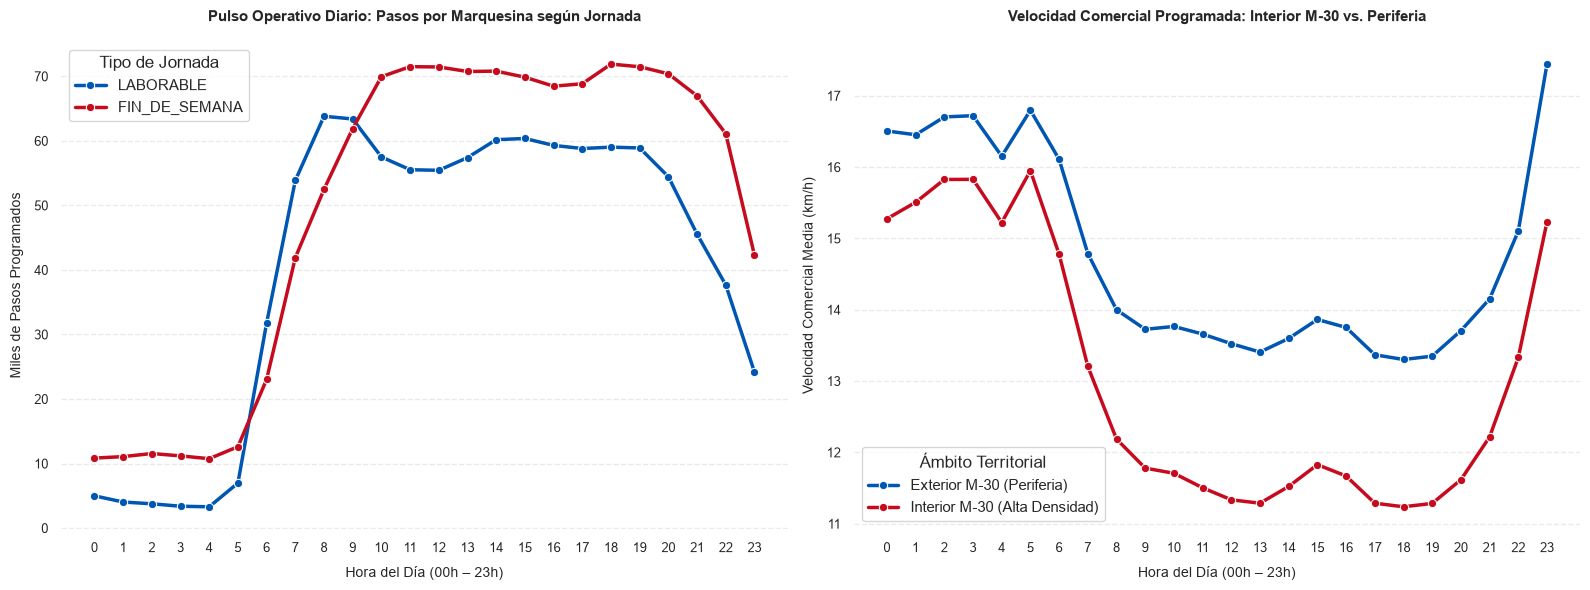

In [6]:
print("====== GENERANDO PANEL 1: PULSO HORARIO Y VELOCIDAD COMERCIAL (M-30) ======\n")

# 1. Agregación horaria por tipo de jornada (Laborable vs Fin de Semana)
df_horario_jornada = (
    df_maestro
    .filter(pl.col("tipo_jornada").is_in(["LABORABLE", "FIN_DE_SEMANA"]))
    .group_by(["hora_entera", "tipo_jornada"])
    .agg(pl.len().alias("total_pasos"))
    .sort("hora_entera")
    .to_pandas()
)

# 2. Velocidad comercial teórica media por hora y ámbito territorial (Interior vs Exterior M-30)
df_vel_territorio = (
    df_maestro
    .filter(pl.col("velocidad_teorica_kmh") > 0)
    .group_by(["hora_entera", "en_alta_densidad_real"])
    .agg(pl.col("velocidad_teorica_kmh").mean().alias("vel_media_kmh"))
    .sort("hora_entera")
    .to_pandas()
)
df_vel_territorio["Zona"] = df_vel_territorio["en_alta_densidad_real"].map({
    True: "Interior M-30 (Alta Densidad)",
    False: "Exterior M-30 (Periferia)"
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- PANEL IZQUIERDO: PULSO HORARIO POR TIPO DE JORNADA ---
paleta_jornada = {
    "LABORABLE": "#0056B3",
    "FIN_DE_SEMANA": "#C60B1E"
}
sns.lineplot(
    data=df_horario_jornada,
    x="hora_entera",
    y=df_horario_jornada["total_pasos"] / 1000.0,
    hue="tipo_jornada",
    palette=paleta_jornada,
    linewidth=2.5,
    marker="o",
    ax=ax1
)
ax1.set_title("Pulso Operativo Diario: Pasos por Marquesina según Jornada", fontsize=11, weight="bold", pad=15)
ax1.set_xlabel("Hora del Día (00h – 23h)", fontsize=10, labelpad=8)
ax1.set_ylabel("Miles de Pasos Programados", fontsize=10, labelpad=8)
ax1.set_xticks(range(0, 24))
ax1.legend(title="Tipo de Jornada", frameon=True, facecolor="white")
ax1.yaxis.grid(True)
ax1.xaxis.grid(False)

# --- PANEL DERECHO: VELOCIDAD COMERCIAL PROGRAMADA (INTERIOR M-30 VS PERIFERIA) ---
paleta_zonas = {
    "Interior M-30 (Alta Densidad)": "#C60B1E",
    "Exterior M-30 (Periferia)": "#0056B3"
}
sns.lineplot(
    data=df_vel_territorio,
    x="hora_entera",
    y="vel_media_kmh",
    hue="Zona",
    palette=paleta_zonas,
    linewidth=2.5,
    marker="o",
    ax=ax2
)
ax2.set_title("Velocidad Comercial Programada: Interior M-30 vs. Periferia", fontsize=11, weight="bold", pad=15)
ax2.set_xlabel("Hora del Día (00h – 23h)", fontsize=10, labelpad=8)
ax2.set_ylabel("Velocidad Comercial Media (km/h)", fontsize=10, labelpad=8)
ax2.set_xticks(range(0, 24))
ax2.legend(title="Ámbito Territorial", frameon=True, facecolor="white")
ax2.yaxis.grid(True)
ax2.xaxis.grid(False)

for ax_canvas in [ax1, ax2]:
    ax_canvas.tick_params(axis="both", labelsize=9.5)
    sns.despine(ax=ax_canvas, top=True, right=True, left=True, bottom=True)

plt.tight_layout()
plt.show()


> **📌 Lectura Operativa del Panel 1:**
> * **Asimetría Horaria (`LABORABLE` vs. `FIN_DE_SEMANA`):** Entre las **06:00h y las 09:00h**, la oferta programada en días laborables supera incluso a la suma combinada de sábados (`SA`) y festivos (`FE`), alcanzando un pico matinal de **~64.000 pasos/hora** a las **08:00h**. Durante la madrugada (`00:00h–04:00h`), el refuerzo de la red nocturna de Búhos en fin de semana duplica el volumen de pasos respecto a una noche laborable.
> * **Brecha Estructural de Velocidad Comercial (M-30):** La velocidad comercial programada en el **Interior de la M-30** cae desde los **15,9 km/h** en madrugada hasta un mínimo de **11,2 km/h** en las franjas centrales del día (`13:00h` y `18:00h`), situándose de forma constante entre **1,5 y 2,3 km/h por debajo de la Periferia Exterior** (`13,3–17,5 km/h`) debido a la mayor densidad semafórica y de cruces urbanos.

#### 3.2. Nodos Críticos de Saturación en Ventanas de 15 Minutos y Distribución por Régimen Operativo

Identificamos los **10 postes físicos y sentidos de marcha con mayor concentración simultánea de expediciones en ventanas de 15 minutos** (`saturacion_marquesina_15min`) junto a su franja horaria exacta, y analizamos la **distribución completa de la velocidad comercial programada** (mediana, dispersión intercuartílica y media) según el régimen operativo del servicio.

====== GENERANDO PANEL 2: NODOS CRÍTICOS (15 MIN) Y DISTRIBUCIÓN POR RÉGIMEN ======



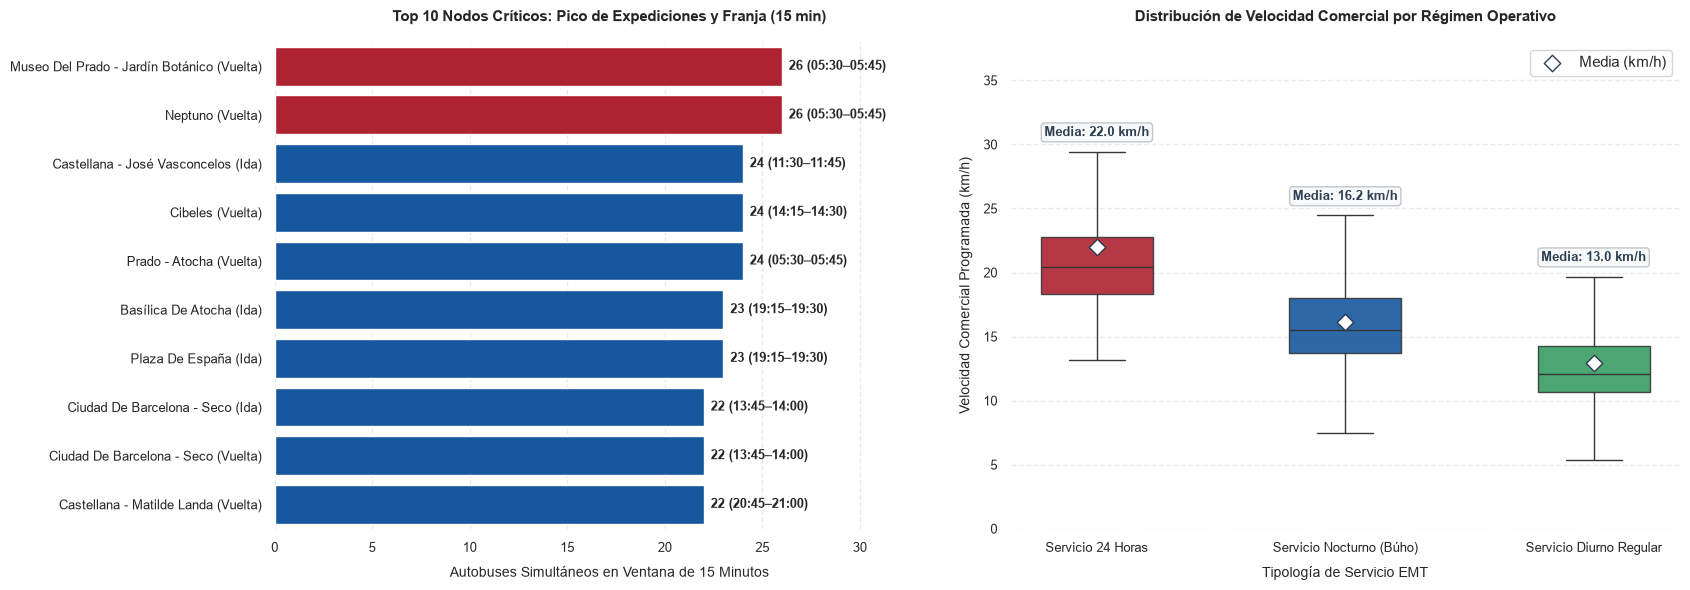

In [7]:
print("====== GENERANDO PANEL 2: NODOS CRÍTICOS (15 MIN) Y DISTRIBUCIÓN POR RÉGIMEN ======\n")

# 1. Identificar el pico máximo de saturación y el tramo exacto de 15 minutos en que ocurre
top_paradas_sat = (
    df_maestro
    .group_by(["stop_id", "stop_name", "direction_id", "tipo_jornada", "tramo_15min", "en_alta_densidad_real"])
    .agg(pl.len().alias("buses_15min"))
    .sort(["buses_15min", "tramo_15min", "stop_id"], descending=[True, False, False])
    .unique(subset=["stop_id", "direction_id"], keep="first")
    .sort(["buses_15min", "stop_id"], descending=[True, False])
    .head(10)
    .to_pandas()
)

def formatear_ventana_15min(tramo):
    min_ini = int(tramo) * 15
    min_fin = min_ini + 15
    h1, m1 = divmod(min_ini, 60)
    h2, m2 = divmod(min_fin, 60)
    return f"{h1:02d}:{m1:02d}–{h2 % 24:02d}:{m2:02d}"

top_paradas_sat["ventana_horaria"] = top_paradas_sat["tramo_15min"].apply(formatear_ventana_15min)
top_paradas_sat["sentido_txt"] = top_paradas_sat["direction_id"].map({0: "Ida", 1: "Vuelta"})
top_paradas_sat["etiqueta"] = (
    top_paradas_sat["stop_name"].str.title() + " (" + top_paradas_sat["sentido_txt"] + ")"
)

# 2. Preparación de datos para el Boxplot de velocidad por régimen operativo
df_vel_regimen = (
    df_maestro
    .filter(pl.col("velocidad_teorica_kmh") > 0)
    .select(["regimen_horario", "velocidad_teorica_kmh"])
    .to_pandas()
)
orden_regimen = ["Servicio 24 Horas", "Servicio Nocturno (Búho)", "Servicio Diurno Regular"]
medias_regimen = df_vel_regimen.groupby("regimen_horario")["velocidad_teorica_kmh"].mean().reindex(orden_regimen)

# Calculamos el techo del bigote superior de cada caja para situar la etiqueta sin tapar nada
techos_bigotes = []
for reg in orden_regimen:
    serie = df_vel_regimen.loc[df_vel_regimen["regimen_horario"] == reg, "velocidad_teorica_kmh"]
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    bigote_sup = serie[serie <= q3 + 1.5 * iqr].max()
    techos_bigotes.append(bigote_sup)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6))

# --- PANEL IZQUIERDO: TOP 10 NODOS CRÍTICOS CON VENTANA HORARIA ---
max_pico_15min = top_paradas_sat["buses_15min"].max()
colores_top10 = [
    "#C60B1E" if val == max_pico_15min else "#0056B3"
    for val in top_paradas_sat["buses_15min"]
]

sns.barplot(
    data=top_paradas_sat,
    x="buses_15min",
    y="etiqueta",
    hue="etiqueta",
    palette=colores_top10,
    legend=False,
    ax=ax1
)

etiquetas_barras = [
    f"{row.buses_15min} ({row.ventana_horaria})"
    for row in top_paradas_sat.itertuples()
]
for container, texto_etiqueta in zip(ax1.containers, etiquetas_barras):
    ax1.bar_label(container, labels=[texto_etiqueta], padding=5, weight="bold", fontsize=9)

ax1.set_title("Top 10 Nodos Críticos: Pico de Expediciones y Franja (15 min)", fontsize=11, weight="bold", pad=15)
ax1.set_xlabel("Autobuses Simultáneos en Ventana de 15 Minutos", fontsize=10, labelpad=8)
ax1.set_ylabel("")
ax1.set_xlim(0, max_pico_15min * 1.32)
ax1.xaxis.grid(True)
ax1.yaxis.grid(False)

# --- PANEL DERECHO: BOXPLOT DE DISTRIBUCIÓN DE VELOCIDADES + MEDIA DESPEJADA ---
paleta_regimen = {
    "Servicio 24 Horas": "#C60B1E",
    "Servicio Nocturno (Búho)": "#0056B3",
    "Servicio Diurno Regular": "#27AE60"
}

sns.boxplot(
    data=df_vel_regimen,
    x="regimen_horario",
    y="velocidad_teorica_kmh",
    order=orden_regimen,
    hue="regimen_horario",
    palette=paleta_regimen,
    legend=False,
    showfliers=False,
    width=0.45,
    boxprops=dict(alpha=0.90),
    ax=ax2
)

# Rombo blanco marcando la media exacta dentro de cada caja
ax2.scatter(
    x=range(len(orden_regimen)),
    y=medias_regimen.values,
    color="white",
    edgecolor="#2C3E50",
    s=70,
    marker="D",
    zorder=5,
    label="Media (km/h)"
)

# Etiqueta de la media colocada limpiamente por encima del bigote superior sin solapar la caja
for idx, (val_media, techo) in enumerate(zip(medias_regimen.values, techos_bigotes)):
    ax2.text(
        idx, techo + 1.0,
        f"Media: {val_media:.1f} km/h",
        ha="center", va="bottom",
        fontsize=9, weight="bold", color="#2C3E50",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="#F8F9FA", edgecolor="#BDC3C7", alpha=0.95)
    )

ax2.set_title("Distribución de Velocidad Comercial por Régimen Operativo", fontsize=11, weight="bold", pad=15)
ax2.set_xlabel("Tipología de Servicio EMT", fontsize=10, labelpad=8)
ax2.set_ylabel("Velocidad Comercial Programada (km/h)", fontsize=10, labelpad=8)
ax2.set_ylim(0, 38)
ax2.legend(loc="upper right", frameon=True, facecolor="white")
ax2.yaxis.grid(True)
ax2.xaxis.grid(False)

for ax_canvas in [ax1, ax2]:
    ax_canvas.tick_params(axis="both", labelsize=9.5)
    sns.despine(ax=ax_canvas, top=True, right=True, left=True, bottom=True)

plt.tight_layout()
plt.show()


> **📌 Lectura Operativa del Panel 2:**
> * **Concentración Absoluta en el Interior de la M-30 (`100%` del Top 10):** La totalidad de los 10 nodos con mayor presión de dársena pertenece al interior de la Almendra Central a lo largo del eje Prado–Recoletos–Castellana, diferenciándose dos ventanas críticas:
>   1. **Relevo Nocturno–Diurno (`05:30–05:45`):** **Museo del Prado - Jardín Botánico (Vuelta)** y **Neptuno (Vuelta)** lideran con **26 expediciones/15 min** (seguidos de **Prado - Atocha (Vuelta)** con **24**), fruto del solapamiento en el corredor Cibeles–Atocha entre los últimos turnos nocturnos de fin de semana y las primeras salidas diurnas.
>
>   2. **Horas Punta de Congestión Diurna:** En horario regular sobresalen los picos de mediodía en **Cibeles (Vuelta)** (`24` buses en `14:15–14:30`), **Ciudad de Barcelona - Seco** en ambos sentidos (`22` buses en `13:45–14:00`), **Castellana - José Vasconcelos (Ida)** (`24` buses en `11:30–11:45`) y el pico vespertino en **Basílica de Atocha (Ida)** y **Plaza de España (Ida)** (`23` buses en `19:15–19:30`).
>
> * **Distribución y Dispersión por Régimen Operativo:** El diagrama de cajas evidencia no solo la brecha en velocidad media, sino también la amplitud operativa de cada servicio: el **Servicio 24 Horas (Exprés Aeropuerto)** alcanza una media de **22,0 km/h** con recorridos que superan los **29 km/h** en vías rápidas; la **Red Nocturna de Búhos** mantiene una distribución intermedia (**16,2 km/h** de media); y el **Servicio Diurno Regular** presenta una banda estrecha y comprimida en torno a los **13,0 km/h**, reflejando el techo estructural impuesto por el tráfico urbano diurno.

## 📋 Conclusiones Ejecutivas y Preparación para el Modelo 1 (*Baseline GTFS*)

1. **Integridad Relacional Certificada:** El ensamblaje de las 8 tablas saneadas del catálogo GTFS consolida **2.232.015 tramos** y **235 líneas operativas activas** con **0 valores nulos**, **0 duplicados** y **0 anomalías cinemáticas** (la única ruta administrativa sin viajes regulares es la `SE721`, servicio discrecional de eventos en el Estadio Metropolitano).

2. **Validación de la Brecha Estructural M-30:** Se confirma cuantitativamente que operar dentro de la Almendra Central penaliza la velocidad comercial programada en **~2 km/h** respecto a la periferia (cayendo hasta **11,2 km/h** en horas centrales), lo que valida la incorporación de `friccion_acumulada_m30` para capturar el efecto arrastre de retrasos.

3. **Identificación Espaciotemporal de Cuellos de Botella (`15 min`):** La segmentación en ventanas de cuarto de hora por poste, sentido y tipo de jornada (`saturacion_marquesina_15min`) aísla tanto el relevo nocturno–diurno (`05:30–05:45`) como las horas punta reales de mediodía (`13:45–14:30`) y tarde (`19:15–19:30`) en el eje Prado–Castellana.

4. **Paso a Producción (`src/consolidacion.py`):** Las nuevas variables validadas (`tipo_jornada`, `indice_sinuosidad_normalizado`, `velocidad_teorica_kmh`, `saturacion_marquesina_15min`, `friccion_acumulada_m30`, `hora_seno` y `hora_coseno`) quedan listas para integrarse directamente en el pipeline de consolidación y alimentar el entrenamiento del **Modelo 1 (*Baseline Estructural GTFS*)**.

---
> **Atribución de Fuente de Datos:** *Powered by [EMT de Madrid](http://www.emtmadrid.es)* (Portal de Datos Abiertos MobilityLabs / Ayuntamiento de Madrid).